# Human Action Recognition — trening 3 modeli (01)

**Przedmiot:** Podstawy reprezentacji i analizy danych
**Typ:** Projekt zaliczeniowy  
**Autorzy:** Artsiom Markevich, Serafim Sidubayeu
**Data:** 31.01.2026
**Zbiór danych:** Human Action Recognition (obrazy + etykiety w pliku CSV)  
**Zadanie:** klasyfikacja obrazu do jednej z 15 klas aktywności (multi-class image classification)

Ten notatnik:
- wczytuje dane z `Training_set.csv` i folderu `train/`
- buduje pipeline `tf.data`
- uczy 3 modele (transfer learning): ResNet50, EfficientNetB0, MobileNetV2
- zapisuje najlepsze modele do `models/` oraz wyniki do `results.json`


## 0) Zależności (jeśli środowisko ich nie ma)

Jeżeli importy w kolejnym kroku nie działają, uruchom:

```bash
pip install -U tensorflow numpy pandas scikit-learn matplotlib
```

W Google Colab:
```bash
!pip install -U tensorflow numpy pandas scikit-learn matplotlib
```


In [1]:
import os, json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("Python:", os.sys.version)
print("TensorFlow:", tf.__version__)


Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
TensorFlow: 2.16.1


In [2]:
SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)


DATA_DIR = Path("./data/Human Action Recognition")
TRAIN_IMG_DIR = DATA_DIR / "train"
CSV_PATH = DATA_DIR / "Training_set.csv"

IMG_SIZE = (160, 160)
BATCH = 16
VAL_SPLIT = 0.2

MODELS_DIR = Path("./models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_DIR:", DATA_DIR.resolve())
print("CSV_PATH exists:", CSV_PATH.exists())
print("TRAIN_IMG_DIR exists:", TRAIN_IMG_DIR.exists())


DATA_DIR: C:\Users\marke\University\Python\PRIADPROJECT\data\Human Action Recognition
CSV_PATH exists: True
TRAIN_IMG_DIR exists: True


In [3]:
if not CSV_PATH.exists():
    raise FileNotFoundError(f"Brak pliku CSV: {CSV_PATH}")

df = pd.read_csv(CSV_PATH)

required_cols = {"filename", "label"}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"CSV nie ma wymaganych kolumn {missing_cols}. Ma kolumny: {list(df.columns)}")

df["path"] = df["filename"].apply(lambda x: str(TRAIN_IMG_DIR / str(x)))

print("Rows:", len(df))
print(df.head(3))


Rows: 12600
      filename         label                                             path
0  Image_1.jpg       sitting  data\Human Action Recognition\train\Image_1.jpg
1  Image_2.jpg  using_laptop  data\Human Action Recognition\train\Image_2.jpg
2  Image_3.jpg       hugging  data\Human Action Recognition\train\Image_3.jpg


In [4]:

missing = [p for p in df["path"].tolist() if not Path(p).exists()]
print("Missing files:", len(missing))

print("Sample missing:", missing[:5])

if len(missing) > 0:
    raise FileNotFoundError(
        "Są brakujące obrazy. Najpierw popraw DATA_DIR / ścieżki do danych. "
        "Przykład brakującej ścieżki: " + str(missing[0])
    )


Missing files: 0
Sample missing: []


In [5]:
class_names = sorted(df["label"].unique())
label_to_id = {name: i for i, name in enumerate(class_names)}
df["label_id"] = df["label"].map(label_to_id)

num_classes = len(class_names)
print("Num classes:", num_classes)
print("Classes:", class_names)

counts = df["label"].value_counts().reindex(class_names)
display(counts.to_frame("count"))


Num classes: 15
Classes: ['calling', 'clapping', 'cycling', 'dancing', 'drinking', 'eating', 'fighting', 'hugging', 'laughing', 'listening_to_music', 'running', 'sitting', 'sleeping', 'texting', 'using_laptop']


,count
label,
calling,840
clapping,840
cycling,840
dancing,840
drinking,840
eating,840
fighting,840
hugging,840
laughing,840


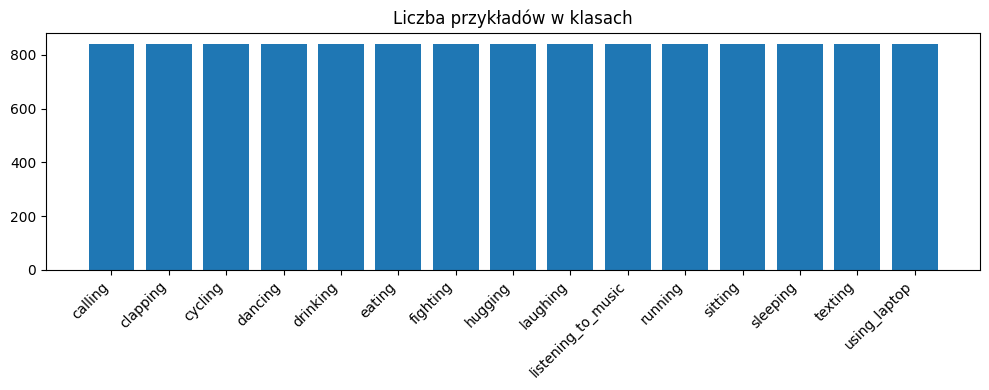

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=45, ha="right")
plt.title("Liczba przykładów w klasach")
plt.tight_layout()
plt.show()


In [7]:
train_df, val_df = train_test_split(
    df,
    test_size=VAL_SPLIT,
    random_state=SEED,
    stratify=df["label_id"]
)

print("Train:", len(train_df), "Val:", len(val_df))

train_counts = train_df["label"].value_counts().reindex(class_names).fillna(0).astype(int)
val_counts = val_df["label"].value_counts().reindex(class_names).fillna(0).astype(int)
display(pd.DataFrame({"train": train_counts, "val": val_counts}))


Train: 10080 Val: 2520


,train,val
label,,
calling,672,168
clapping,672,168
cycling,672,168
dancing,672,168
drinking,672,168
eating,672,168
fighting,672,168
hugging,672,168
laughing,672,168


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)  # 0..255
    return img, label

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["path"].values, train_df["label_id"].values)
).shuffle(4000, seed=SEED).map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["path"].values, val_df["label_id"].values)
).map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

for x, y in train_ds.take(1):
    print("Batch images:", x.shape, x.dtype, "Batch labels:", y.shape, y.dtype)


Batch images: (16, 160, 160, 3) <dtype: 'float32'> Batch labels: (16,) <dtype: 'int64'>


In [9]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augment")


In [10]:
def build_model(backbone_name: str):
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)

    if backbone_name == "resnet50":
        preprocess = keras.applications.resnet.preprocess_input
        base = keras.applications.ResNet50(
            include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,)
        )
    elif backbone_name == "efficientnetb0":
        preprocess = keras.applications.efficientnet.preprocess_input
        base = keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,)
        )
    elif backbone_name == "mobilenetv2":
        preprocess = keras.applications.mobilenet_v2.preprocess_input
        base = keras.applications.MobileNetV2(
            include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,)
        )
    else:
        raise ValueError("Unknown backbone_name")

    base.trainable = False

    x = preprocess(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.25)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name=f"har_{backbone_name}")
    return model, base


In [11]:
def train_one(name: str):
    model, base = build_model(name)

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    ckpt_path = MODELS_DIR / f"best_{name}.keras"
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_accuracy", save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6),
    ]

    history1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=4,
        callbacks=callbacks,
        verbose=1,
    )

    base.trainable = True
    fine_tune_at = int(len(base.layers) * 0.7)
    for layer in base.layers[:fine_tune_at]:
        layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(1e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    history2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        callbacks=callbacks,
        verbose=1,
    )

    best = keras.models.load_model(str(ckpt_path))

    y_true = np.concatenate([y.numpy() for _, y in val_ds], axis=0)
    y_prob = best.predict(val_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    acc = float((y_pred == y_true).mean())
    rep = classification_report(
        y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0
    )
    macro_f1 = float(rep["macro avg"]["f1-score"])
    cm = confusion_matrix(y_true, y_pred).tolist()

    final_path = MODELS_DIR / f"{name}.keras"
    best.save(str(final_path))

    return {
        "model": name,
        "val_acc": acc,
        "macro_f1": macro_f1,
        "checkpoint": str(ckpt_path),
        "saved_model": str(final_path),
        "report": rep,
        "cm": cm,
    }


In [12]:
results = []
for name in ["resnet50", "efficientnetb0", "mobilenetv2"]:
    r = train_one(name)
    results.append(r)
    print("DONE:", name, "val_acc=", r["val_acc"], "macro_f1=", r["macro_f1"])

out_json = Path("results.json")
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

with open("classes.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

print("Saved:", out_json.resolve())
print("Saved:", Path("classes.json").resolve())
print("Saved models in:", MODELS_DIR.resolve())


Epoch 1/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 67s 101ms/step - accuracy: 0.3832 - loss: 2.2030 - val_accuracy: 0.6000 - val_loss: 1.3022 - learning_rate: 0.0010
Epoch 2/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.5697 - loss: 1.4333 - val_accuracy: 0.5988 - val_loss: 1.4036 - learning_rate: 0.0010
Epoch 3/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 62s 98ms/step - accuracy: 0.6229 - loss: 1.1986 - val_accuracy: 0.6353 - val_loss: 1.1868 - learning_rate: 5.0000e-04
Epoch 4/4
630/630 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.6293 - loss: 1.1627 - val_accuracy: 0.6512 - val_loss: 1.1539 - learning_rate: 5.0000e-04
Epoch 1/3
630/630 ━━━━━━━━━━━━━━━━━━━━ 114s 173ms/step - accuracy: 0.5910 - loss: 1.2877 - val_accuracy: 0.6841 - val_loss: 1.0466 - learning_rate: 1.0000e-04
Epoch 2/3
630/630 ━━━━━━━━━━━━━━━━━━━━ 107s 170ms/step - accuracy: 0.7493 - loss: 0.7907 - val_accuracy: 0.7032 - val_loss: 1.0255 - learning_rate: 1.0000e-04
Epoch 3/3
630/630 ━━━━━━━━━━━━━━━━━━━━ 109s 174ms/step - accu